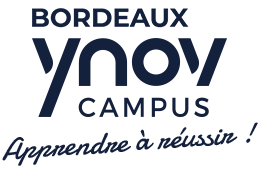

# TP3 — Prévoir la consommation électrique française : baselines → SARIMAX → LSTM → CNN-1D

> **Cours Deep Learning · Ynov Bordeaux · EIA Mastère 2** — TP3 (J3)
> 2h en séance (4h de contenu : parties D à G pour ceux qui finissent en avance) · Résultat attendu en fin de séance : tableau comparatif sur 3 plis du protocole du projet, MAE par jour, figure du 1er mai, conclusion argumentée

**Comment travailler :** exécutez les cellules dans l'ordre. Les cellules marquées `# TODO` sont à compléter. Utilisez `assert` sur les formes dès que vous manipulez des tenseurs. Une cellule à compléter échoue tant que son `TODO` n'est pas fait : c'est normal. Le TP se termine en séance et le corrigé est distribué en fin de TP ; il n'y a rien à rendre.

## Données : le jeu de données du projet

Ce TP travaille directement sur le fichier du projet, **la consommation électrique horaire de la France métropolitaine** (RTE éCO2mix, 2012-2024, 113 976 heures) avec la température de huit villes et le calendrier. Ce que vous construisez aujourd'hui (exploration, baselines, SARIMAX, premier LSTM, premier réseau convolutif 1D, tableau comparatif) est la **première brique de votre projet** : copiez ce notebook dans votre dépôt à la fin de la séance.

**Organisation du TP** : les parties A, B et C sont le tronc commun (2 h en séance) ; les parties D à G, « pour ceux qui finissent en avance », ajoutent 2 h de contenu (analyse d'erreurs, douze plis, ablation, recherche d'hyperparamètres). Rien n'est à rendre.

Le protocole d'évaluation est celui de la fiche projet : horizon 24 h, prévision faite à minuit, douze plis mensuels sur 2024 (sept premiers jours de chaque mois). Pour tenir en deux heures, le TP n'utilise que **trois des douze plis** (janvier, mai, août) ; le passage aux douze plis est une seule ligne à changer.

Le fichier `conso_france_horaire.csv` doit être dans `data/` (sur Colab : `from google.colab import files; files.upload()` puis déplacer le fichier).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, time, os, warnings; warnings.filterwarnings("ignore")
CANDIDATS = ["data/conso_france_horaire.csv", "conso_france_horaire.csv", "../projet/data/conso_france_horaire.csv", "../../projet/data/conso_france_horaire.csv", "../../../projet/data/conso_france_horaire.csv"]   # dossier du TP, ou corriges/, ou copie locale
path = next((p for p in CANDIDATS if os.path.exists(p)), None)
assert path, "conso_france_horaire.csv introuvable : copiez le fichier du projet dans data/"
df = pd.read_csv(path)
df.index = pd.to_datetime(df["datetime"], utc=True).dt.tz_convert("Europe/Paris"); df = df.drop(columns="datetime")
y = df["consommation_mw"]
print(df.shape, "|", df.index.min().date(), "->", df.index.max().date(), "| valeurs manquantes :", int(df.isna().sum().sum()))
df.head(3)

(113976, 14) | 2012-01-01 -> 2024-12-31 | valeurs manquantes : 0


,consommation_mw,temperature_c,temp_paris,temp_lyon,temp_marseille,temp_lille,temp_bordeaux,temp_nantes,temp_strasbourg,temp_toulouse,jour_ferie,jour_semaine,heure,mois
datetime,,,,,,,,,,,,,,
2012-01-01 00:00:00+01:00,58315.0,11.04,12.0,8.6,11.7,11.2,12.6,12.0,9.1,11.1,1,6,0,1
2012-01-01 01:00:00+01:00,56153.0,11.04,12.1,8.6,11.5,11.1,12.6,12.2,9.1,11.1,1,6,1,1
2012-01-01 02:00:00+01:00,55221.5,10.95,12.1,8.4,11.3,11.0,12.5,12.1,9.1,11.1,1,6,2,1


## Partie A — Exploration, stationnarité, baselines (30 min)

### A1 — Les quatre figures qui valent une heure de modélisation (10 min)
Une semaine d'hiver, une semaine d'été, la consommation en fonction de la température, la moyenne par heure et jour de semaine. Puis la moyenne annuelle, pour repérer les deux ruptures de régime (2020, hiver 2022-2023).

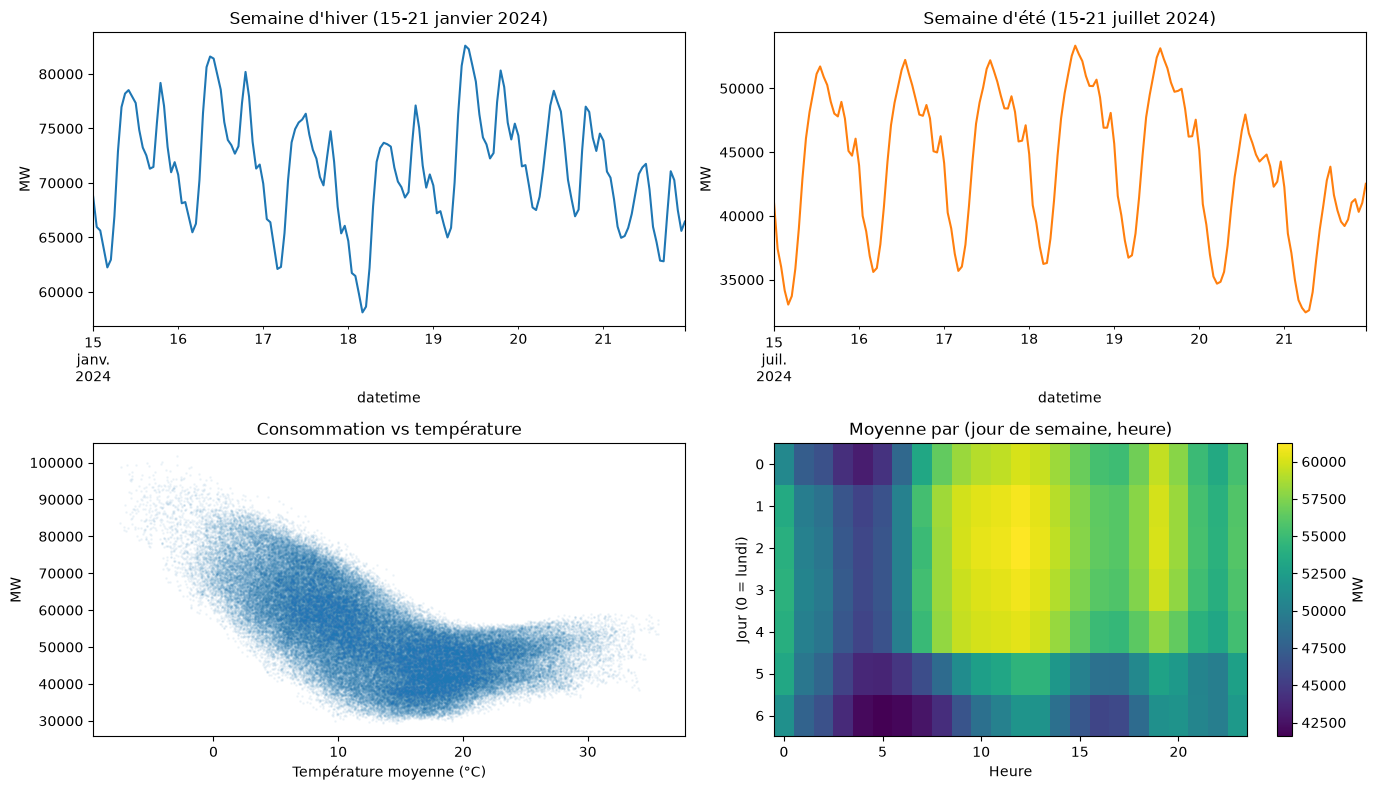

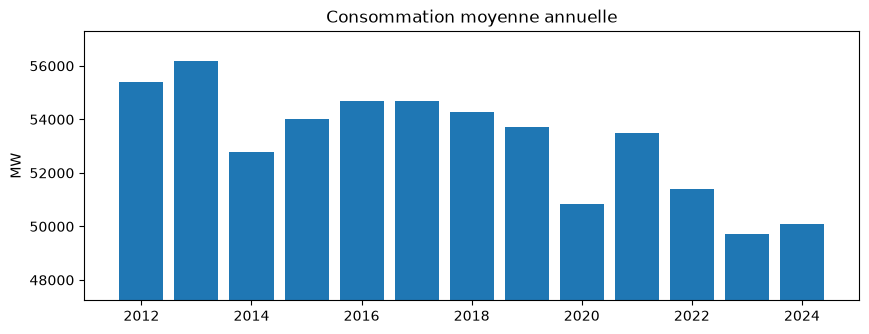

Moyenne : 53,174 MW | min : 29,364 MW (2020-05-10 07:00:00+02:00) | max : 101,650 MW, record le 2012-02-08 19:00:00+01:00


In [2]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
y["2024-01-15":"2024-01-21"].plot(ax=ax[0, 0], title="Semaine d'hiver (15-21 janvier 2024)"); ax[0, 0].set_ylabel("MW")
y["2024-07-15":"2024-07-21"].plot(ax=ax[0, 1], title="Semaine d'été (15-21 juillet 2024)", color="tab:orange"); ax[0, 1].set_ylabel("MW")
ax[1, 0].scatter(df["temperature_c"], y, s=1, alpha=0.05)
ax[1, 0].set(title="Consommation vs température", xlabel="Température moyenne (°C)", ylabel="MW")
prof = y.groupby([df["jour_semaine"], df["heure"]]).mean().unstack()       # (7 jours, 24 heures)
im = ax[1, 1].imshow(prof.values, aspect="auto", cmap="viridis")
ax[1, 1].set(title="Moyenne par (jour de semaine, heure)", xlabel="Heure", ylabel="Jour (0 = lundi)")
fig.colorbar(im, ax=ax[1, 1], label="MW"); plt.tight_layout(); plt.show()

annuelle = y.groupby(y.index.year).mean()
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(annuelle.index, annuelle.values); ax.set_ylim(annuelle.min() * 0.95, annuelle.max() * 1.02)
ax.set(title="Consommation moyenne annuelle", ylabel="MW"); plt.show()
print(f"Moyenne : {y.mean():,.0f} MW | min : {y.min():,.0f} MW ({y.idxmin()}) | max : {y.max():,.0f} MW, record le {y.idxmax()}")
# Ruptures visibles : 2020 (confinement, minimum le 10 mai 2020) et 2022-2023 (sobriété / prix de l'énergie : niveau durablement plus bas)

### A2 — Décomposition, stationnarité, ACF et PACF (8 min)
Sur quatre semaines de janvier 2024, pour lire la saisonnalité de 24 h et choisir la différenciation.

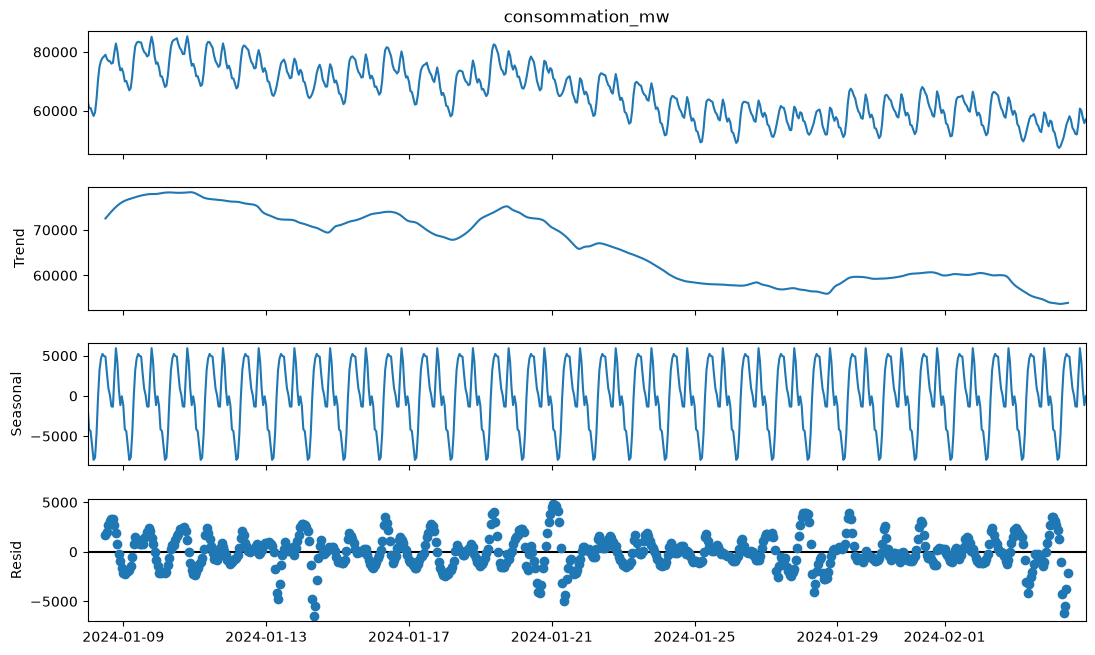

ADF y4           : statistique =   0.10, p-value = 0.9658 -> non stationnaire
ADF y4.diff(24)  : statistique =  -4.50, p-value = 0.0002 -> stationnaire


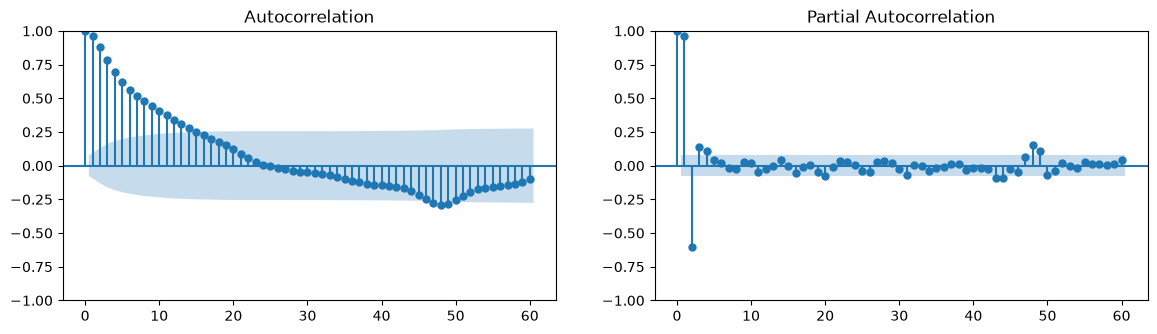

ACF de la série différenciée au retard 168 : 0.247


In [3]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
y4 = y["2024-01-08":"2024-02-04"]
seasonal_decompose(y4, period=24).plot().set_size_inches(12, 7); plt.show()
for nom, s in [("y4", y4), ("y4.diff(24)", y4.diff(24).dropna())]:
    stat, p, *_ = adfuller(s)
    print(f"ADF {nom:12s} : statistique = {stat:6.2f}, p-value = {p:.4f} -> {'stationnaire' if p < 0.05 else 'non stationnaire'}")
d24 = y4.diff(24).dropna()
fig, ax = plt.subplots(1, 2, figsize=(14, 3.5))
plot_acf(d24, lags=60, ax=ax[0]); plot_pacf(d24, lags=60, ax=ax[1], method="ywm"); plt.show()
print("ACF de la série différenciée au retard 168 :", round(acf(d24, nlags=168)[168], 3))
# Au retard 168 il reste une autocorrélation nette : diff(24) retire le cycle journalier
# mais pas la saisonnalité hebdomadaire (semaine / week-end), que le SARIMA(…)(…)24 ne modélise pas.

### A3 — Le protocole commun et les baselines (12 min)
Pour le pli du mois m, on entraîne sur tout ce qui précède le 1er du mois et on prévoit les sept premiers jours, **jour par jour, à minuit**, avec tout l'historique connu à ce moment-là. Toutes les méthodes, aujourd'hui et dans le projet, sont évaluées exactement ainsi, et une seule MAE (et MAPE) par méthode entre dans le tableau.

In [4]:
H = 24
MOIS_TP = [1, 5, 8]                      # trois plis pour le TP ; pour le projet : list(range(1, 13))
jour = df.index.strftime("%Y-%m-%d").values
def plis(mois):
    out = []
    for m in mois:
        debut = np.flatnonzero(jour == f"2024-{m:02d}-01")[0]
        tr = np.arange(debut)                                                  # tout ce qui précède le 1er du mois
        jours = [np.flatnonzero(jour == f"2024-{m:02d}-{d:02d}") for d in range(1, 8)]
        assert all(len(te) == H for te in jours)
        out.append((tr, jours))
    return out
folds = plis(MOIS_TP)
def metrics(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    e = y_true - y_pred
    return {"MAE (MW)": np.mean(np.abs(e)), "RMSE (MW)": np.sqrt(np.mean(e ** 2)), "MAPE (%)": 100 * np.mean(np.abs(e / y_true))}
PREDS = {}
yv = y.values.astype(float)
def evaluate_method(predict_fn, name):
    vrai, pred = [], []
    for tr, jours in folds:
        p = predict_fn(tr, jours)
        assert len(p) == len(jours) and all(len(pi) == H for pi in p)
        for te, pi in zip(jours, p):
            vrai.append(yv[te]); pred.append(np.asarray(pi, float))
    PREDS[name] = np.concatenate(pred)
    return pd.Series(metrics(np.concatenate(vrai), PREDS[name]), name=name)
# chaque journée te est prévue à minuit : on n'utilise que l'historique yv[:te[0]]
derniere = lambda tr, jours: [np.full(H, yv[te[0] - 1]) for te in jours]
veille   = lambda tr, jours: [yv[te - 24] for te in jours]
semaine  = lambda tr, jours: [yv[te - 168] for te in jours]
scores = pd.DataFrame([evaluate_method(derniere, "dernière valeur connue"),
                       evaluate_method(veille, "même heure la veille"),
                       evaluate_method(semaine, "même heure la semaine précédente")])
assert sum(len(te) for _, jours in folds for te in jours) == 504
scores.round(1)

,MAE (MW),RMSE (MW),MAPE (%)
dernière valeur connue,4420.1,5324.7,9.9
même heure la veille,2877.2,3967.7,6.1
même heure la semaine précédente,3774.3,5092.5,7.8


## Partie B — SARIMA et SARIMAX (35 min)
Une estimation par pli sur les trois dernières semaines (une série de 13 ans ne s'estime pas en séance), puis, chaque jour, on **met à jour l'état** du modèle avec les 21 derniers jours (`res.apply`) sans ré-estimer les paramètres, et on prévoit 24 h. SARIMAX ajoute la température, supposée connue pour les 24 h à venir (prévision météo parfaite, comme dans le protocole).

In [5]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
X = df[["temperature_c"]].values.astype(float)
def sarimax_factory(order=(1, 0, 1), seasonal=(1, 1, 1, 24), exog=True, n_fit=24 * 21):
    def predict(tr, jours):
        fit_idx = tr[-n_fit:]                                                  # les 3 dernières semaines du train
        res = SARIMAX(yv[fit_idx], exog=X[fit_idx] if exog else None, order=order, seasonal_order=seasonal).fit(disp=False)
        out = []
        for te in jours:
            hist = np.arange(te[0] - n_fit, te[0])                             # les 21 jours connus à minuit
            r = res.apply(yv[hist], exog=X[hist] if exog else None)            # mise à jour de l'état, mêmes paramètres
            out.append(r.get_forecast(len(te), exog=X[te] if exog else None).predicted_mean)
        return out
    return predict
t0 = time.time()
scores = pd.concat([scores, pd.DataFrame([evaluate_method(sarimax_factory(exog=False), "SARIMA"),
                                          evaluate_method(sarimax_factory(exog=True), "SARIMAX + température")])])
print(f"SARIMA + SARIMAX : {time.time() - t0:.0f} s")
scores.round(1)
# Optionnel : pmdarima.auto_arima(y.values[fit_idx], seasonal=True, m=24) pour choisir l'ordre par AIC

c:\Users\darkj\Desktop\Doc_Ynov\DATA\M2\Deep_Learning\deep_learning\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\darkj\Desktop\Doc_Ynov\DATA\M2\Deep_Learning\deep_learning\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\darkj\Desktop\Doc_Ynov\DATA\M2\Deep_Learning\deep_learning\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\Users\darkj\Desktop\Doc_Ynov\DATA\M2\Deep_Learning\deep_learning\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
c:\

SARIMA + SARIMAX : 36 s


,MAE (MW),RMSE (MW),MAPE (%)
dernière valeur connue,4420.1,5324.7,9.9
même heure la veille,2877.2,3967.7,6.1
même heure la semaine précédente,3774.3,5092.5,7.8
SARIMA,2822.3,3975.6,5.9
SARIMAX + température,2332.9,3463.1,4.9


### Diagnostic des résidus et prévision avec intervalle
Sur le dernier pli (août 2024), premier jour : le 1er août.

c:\Users\darkj\Desktop\Doc_Ynov\DATA\M2\Deep_Learning\deep_learning\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


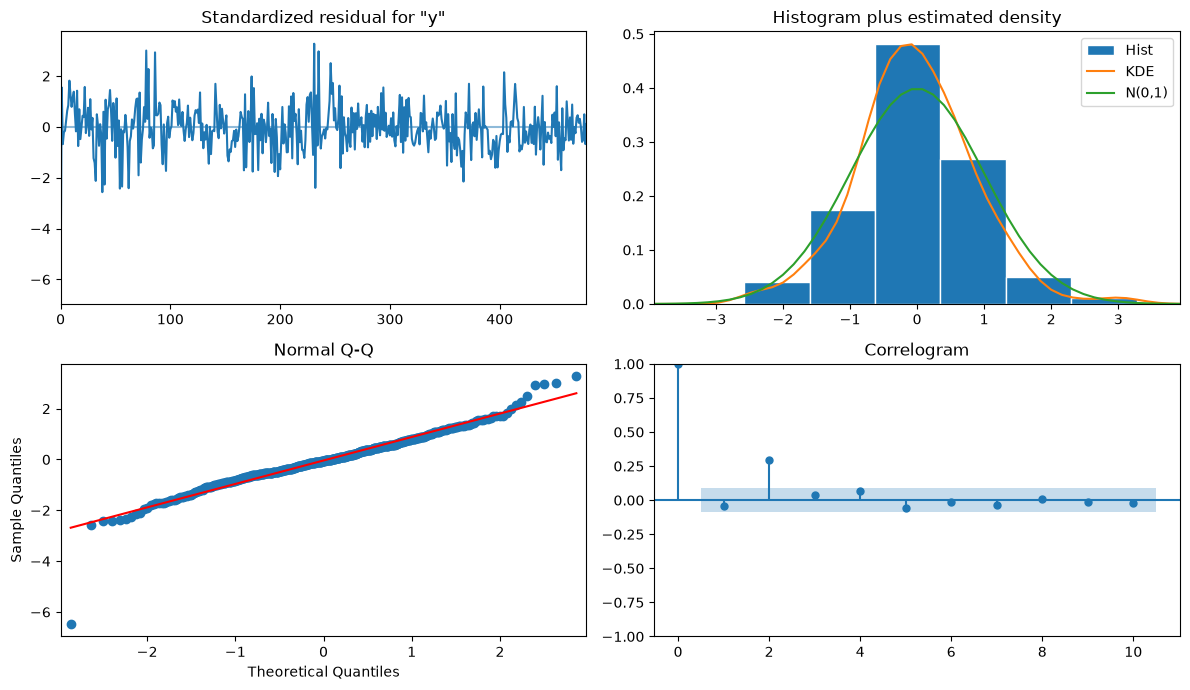

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
x1          1879.6471     16.701    112.545      0.000    1846.913    1912.381
ar.L1          0.9319      0.018     52.266      0.000       0.897       0.967
ma.L1          0.5966      0.041     14.511      0.000       0.516       0.677
ar.S.L24       0.4508      0.054      8.279      0.000       0.344       0.557
ma.S.L24      -0.9967      0.081    -12.337      0.000      -1.155      -0.838
sigma2      5.023e+05   1.27e-05   3.97e+10      0.000    5.02e+05    5.02e+05
AIC = 7653


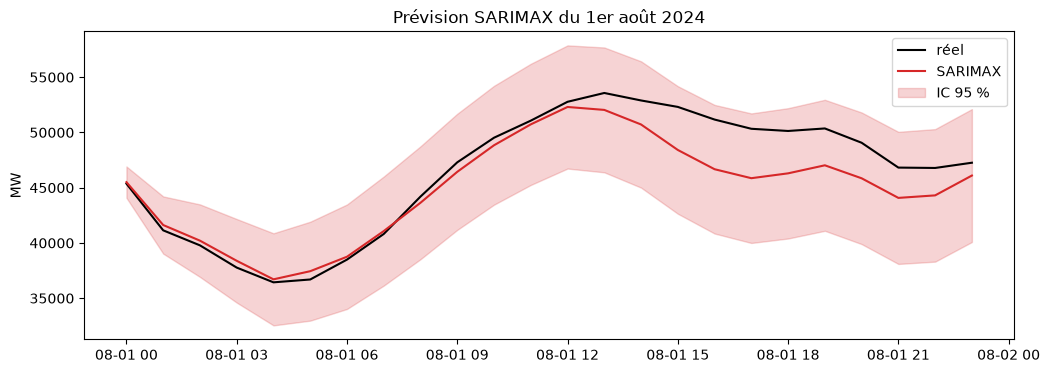

MAE du 1er août : 1,643 MW | couverture de l'IC 95 % : 100%


In [6]:
te = np.flatnonzero(jour == "2024-08-01")
fit_idx = np.arange(te[0] - 24 * 21, te[0])                                    # 3 semaines avant le 1er août
res = SARIMAX(yv[fit_idx], exog=X[fit_idx], order=(1, 0, 1), seasonal_order=(1, 1, 1, 24)).fit(disp=False)
res.plot_diagnostics(figsize=(12, 7)); plt.tight_layout(); plt.show()
print(res.summary().tables[1]); print(f"AIC = {res.aic:.0f}")

fc = res.get_forecast(len(te), exog=X[te])
moy, ci = fc.predicted_mean, fc.conf_int(alpha=0.05)
heures = df.index[te]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(heures, yv[te], "k", label="réel")
ax.plot(heures, moy, "tab:red", label="SARIMAX")
ax.fill_between(heures, ci[:, 0], ci[:, 1], color="tab:red", alpha=0.2, label="IC 95 %")
ax.set(title="Prévision SARIMAX du 1er août 2024", ylabel="MW"); ax.legend(); plt.show()
print(f"MAE du 1er août : {np.mean(np.abs(yv[te] - moy)):,.0f} MW | couverture de l'IC 95 % : {np.mean((yv[te] >= ci[:, 0]) & (yv[te] <= ci[:, 1])):.0%}")

## Partie C — LSTM et réseau convolutif 1D (55 min)
Fenêtre de 168 h en entrée (7 variables : consommation, température, heure et jour de semaine en sinus et cosinus, jour férié), **plus les 24 h de covariables connues à l'avance** (température prévue et calendrier du lendemain), concaténées avant la tête de prédiction. Entraînement sur les **trois dernières années** avant chaque pli ; la normalisation utilise les statistiques du train du pli seulement. GPU recommandé ; sur CPU, comptez une dizaine de minutes pour l'ensemble.

In [8]:
import torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
torch.manual_seed(0); device = "cuda" if torch.cuda.is_available() else "cpu"
W, ANNEES_TRAIN = 168, 3

# --- Matrice de variables (T, 7) : la consommation en colonne 0, puis les covariables connues à l'avance
h, d = df["heure"].values, df["jour_semaine"].values
Z = np.column_stack([df["consommation_mw"], df["temperature_c"],
                     np.sin(2 * np.pi * h / 24), np.cos(2 * np.pi * h / 24),
                     np.sin(2 * np.pi * d / 7), np.cos(2 * np.pi * d / 7),
                     df["jour_ferie"]]).astype(np.float32)
N_IN, N_FUT = Z.shape[1], Z.shape[1] - 1
assert Z.shape == (len(df), 7)

# --- Fenêtrage : entrée passée (W, 7), covariables du lendemain (H, 6), cible (H,)
def make_windows(Zn, starts):
    ip = starts[:, None] + np.arange(W)                 # (N, W)
    jf = starts[:, None] + W + np.arange(H)             # (N, H)
    return Zn[ip], Zn[jf, 1:], Zn[jf, 0]

def starts_train(tr, max_windows):
    fin = tr[-1] + 1                                     # première heure hors train
    s_max = fin - W - H                                  # la cible doit finir dans le train
    return np.arange(max(0, s_max - max_windows + 1), s_max + 1)

# --- Deux familles de réseaux, même tête : résumé du passé + covariables du lendemain -> H valeurs
class Tete(nn.Module):
    def __init__(self, n_resume, n_fut, dropout):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(n_resume + H * n_fut, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, H))
    def forward(self, resume, xf):
        return self.net(torch.cat([resume, xf.flatten(1)], dim=1))

class LSTMForecaster(nn.Module):
    def __init__(self, n_in=N_IN, n_fut=N_FUT, hidden=64, dropout=0.1):
        super().__init__()
        self.lstm = nn.LSTM(n_in, hidden, batch_first=True)
        self.drop = nn.Dropout(dropout)
        self.tete = Tete(hidden, n_fut, dropout)
    def forward(self, xp, xf):                           # xp (B, W, n_in), xf (B, H, n_fut)
        _, (hn, _) = self.lstm(xp)
        return self.tete(self.drop(hn[-1]), xf)          # (B, H)

class CNNForecaster(nn.Module):
    def __init__(self, n_in=N_IN, n_fut=N_FUT, hidden=64, dropout=0.1):
        super().__init__()
        self.conv = nn.Sequential(                       # convolutions dilatées : champ récepteur ~ 1 semaine
            nn.Conv1d(n_in, 32, 5, padding=2), nn.ReLU(),
            nn.Conv1d(32, 64, 5, padding=4, dilation=2), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, hidden, 5, padding=8, dilation=4), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(hidden, hidden, 5, padding=16, dilation=8), nn.ReLU())
        self.drop = nn.Dropout(dropout)
        self.tete = Tete(2 * hidden, n_fut, dropout)
    def forward(self, xp, xf):
        c = self.conv(xp.transpose(1, 2))                # (B, hidden, T')
        resume = torch.cat([c.mean(dim=2), c[:, :, -1]], dim=1)   # pooling global + dernier pas (le plus récent)
        return self.tete(self.drop(resume), xf)

def n_params(m): return sum(p.numel() for p in m.parameters())

# --- Entraînement et prédiction au format evaluate_method
def dl_factory(model_cls=LSTMForecaster, epochs=8, max_windows=24 * 365 * ANNEES_TRAIN, lr=1e-3, hidden=64, dropout=0.1,
               batch_size=256, seed=0, verbose=True):
    def predict(tr, jours):
        torch.manual_seed(seed); np.random.seed(seed)
        mu, sd = Z[tr].mean(axis=0), Z[tr].std(axis=0) + 1e-6       # statistiques du train du pli seulement
        Zn = (Z - mu) / sd
        xp, xf, yt = make_windows(Zn, starts_train(tr, max_windows))
        dl = DataLoader(TensorDataset(*map(torch.from_numpy, (xp, xf, yt))), batch_size=batch_size, shuffle=True)
        model = model_cls(hidden=hidden, dropout=dropout).to(device)
        opt, loss_fn = torch.optim.Adam(model.parameters(), lr=lr), nn.L1Loss()
        for ep in range(epochs):
            model.train(); tot = 0.0
            for bp, bf, by in dl:
                bp, bf, by = bp.to(device), bf.to(device), by.to(device)
                opt.zero_grad(); loss = loss_fn(model(bp, bf), by); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
                tot += loss.item() * len(by)
            if verbose: print(f"  {model_cls.__name__} | epoch {ep + 1}/{epochs} | L1 train (MW) = {tot / len(yt) * sd[0]:,.0f}")
        model.eval(); predict.model = model
        with torch.no_grad():
            xp_t = torch.from_numpy(np.stack([Zn[te[0] - W:te[0]] for te in jours])).to(device)
            xf_t = torch.from_numpy(np.stack([Zn[te, 1:] for te in jours])).to(device)
            p = model(xp_t, xf_t).cpu().numpy()
        return list(p * sd[0] + mu[0])                    # dénormalisation
    return predict

xp0, xf0, y0 = make_windows(Z, np.array([0, 1]))
assert xp0.shape == (2, W, N_IN) and xf0.shape == (2, H, N_FUT) and y0.shape == (2, H)

t0 = time.time(); lstm_fn = dl_factory(LSTMForecaster)
s_lstm = evaluate_method(lstm_fn, "LSTM"); t_lstm = time.time() - t0
t0 = time.time(); cnn_fn = dl_factory(CNNForecaster)
s_cnn = evaluate_method(cnn_fn, "CNN-1D"); t_cnn = time.time() - t0
scores = pd.concat([scores, pd.DataFrame([s_lstm, s_cnn])])
print(f"LSTM : {n_params(lstm_fn.model):,} paramètres, {t_lstm:.0f} s | CNN-1D : {n_params(cnn_fn.model):,} paramètres, {t_cnn:.0f} s")
scores.round(1)

  LSTMForecaster | epoch 1/8 | L1 train (MW) = 3,754
  LSTMForecaster | epoch 2/8 | L1 train (MW) = 2,044
  LSTMForecaster | epoch 3/8 | L1 train (MW) = 1,824
  LSTMForecaster | epoch 4/8 | L1 train (MW) = 1,695
  LSTMForecaster | epoch 5/8 | L1 train (MW) = 1,621
  LSTMForecaster | epoch 6/8 | L1 train (MW) = 1,570
  LSTMForecaster | epoch 7/8 | L1 train (MW) = 1,545
  LSTMForecaster | epoch 8/8 | L1 train (MW) = 1,518
  LSTMForecaster | epoch 1/8 | L1 train (MW) = 3,585
  LSTMForecaster | epoch 2/8 | L1 train (MW) = 1,979
  LSTMForecaster | epoch 3/8 | L1 train (MW) = 1,769
  LSTMForecaster | epoch 4/8 | L1 train (MW) = 1,656
  LSTMForecaster | epoch 5/8 | L1 train (MW) = 1,578
  LSTMForecaster | epoch 6/8 | L1 train (MW) = 1,538
  LSTMForecaster | epoch 7/8 | L1 train (MW) = 1,498
  LSTMForecaster | epoch 8/8 | L1 train (MW) = 1,460
  LSTMForecaster | epoch 1/8 | L1 train (MW) = 3,590
  LSTMForecaster | epoch 2/8 | L1 train (MW) = 1,949
  LSTMForecaster | epoch 3/8 | L1 train (MW) =

,MAE (MW),RMSE (MW),MAPE (%)
dernière valeur connue,4420.1,5324.7,9.9
même heure la veille,2877.2,3967.7,6.1
même heure la semaine précédente,3774.3,5092.5,7.8
SARIMA,2822.3,3975.6,5.9
SARIMAX + température,2332.9,3463.1,4.9
LSTM,1319.5,1672.9,2.8
CNN-1D,1450.2,1890.0,3.1


### Tableau final, figure et erreur jour par jour
Le tableau est **le** résultat : baselines en première ligne, toutes les méthodes sur les mêmes 504 heures. Puis l'erreur par jour : où les réseaux gagnent-ils ? Regardez le 1er mai (férié) et le 8 mai.

                                  MAE (MW)  RMSE (MW)  MAPE (%)
LSTM                                1319.5     1672.9       2.8
CNN-1D                              1450.2     1890.0       3.1
SARIMAX + température               2332.9     3463.1       4.9
SARIMA                              2822.3     3975.6       5.9
même heure la veille                2877.2     3967.7       6.1
même heure la semaine précédente    3774.3     5092.5       7.8
dernière valeur connue              4420.1     5324.7       9.9


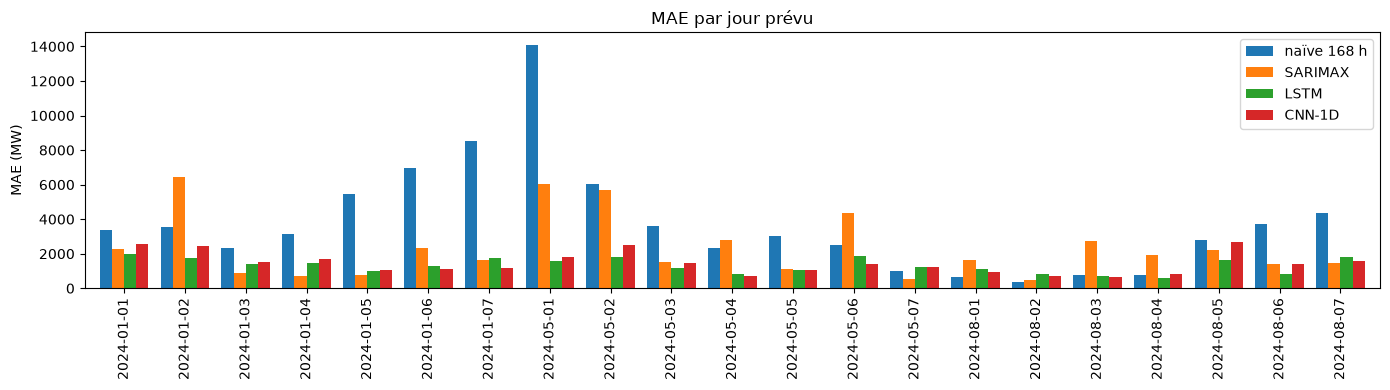

            naïve 168 h  SARIMAX    LSTM  CNN-1D
2024-05-01      14110.0   6063.0  1569.0  1783.0
2024-05-02       6013.0   5717.0  1822.0  2513.0
2024-05-03       3623.0   1507.0  1150.0  1439.0
2024-05-04       2344.0   2809.0   801.0   698.0
2024-05-05       2998.0   1091.0  1079.0  1062.0
2024-05-06       2492.0   4369.0  1859.0  1411.0
2024-05-07        981.0    524.0  1245.0  1204.0


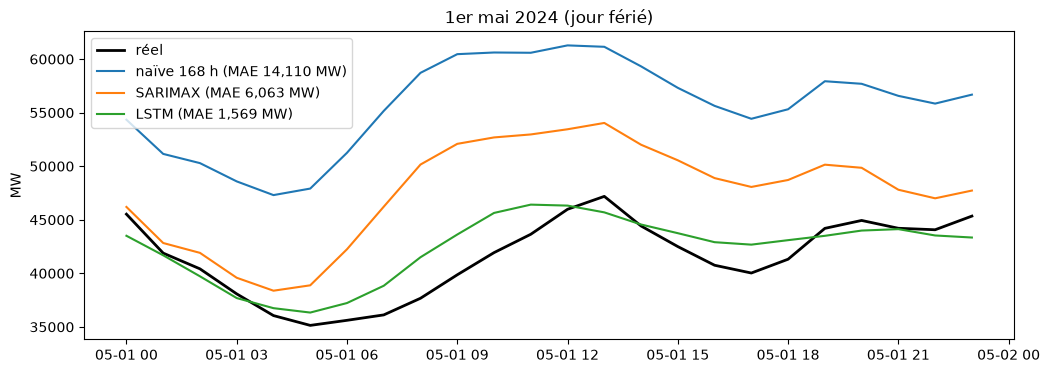

In [9]:
print(scores.sort_values("MAE (MW)").round(1))

# MAE par jour (21 jours) : PREDS stocke les plis dans l'ordre, 24 heures par jour
dates = [jour[te[0]] for _, jours in folds for te in jours]
reel = np.concatenate([yv[te] for _, jours in folds for te in jours]).reshape(-1, H)
compar = {"naïve 168 h": "même heure la semaine précédente", "SARIMAX": "SARIMAX + température", "LSTM": "LSTM", "CNN-1D": "CNN-1D"}
mae_jour = pd.DataFrame({lab: np.abs(PREDS[nom].reshape(-1, H) - reel).mean(axis=1) for lab, nom in compar.items()}, index=dates)
ax = mae_jour.plot.bar(figsize=(14, 4), width=0.8)
ax.set(title="MAE par jour prévu", ylabel="MAE (MW)"); plt.tight_layout(); plt.show()
print(mae_jour.round(0).loc["2024-05-01":"2024-05-07"])   # le pli de mai : 1er au 7 (le 8 mai est hors protocole)

# Le 1er mai 2024 (férié)
k = dates.index("2024-05-01"); te = folds[1][1][0]
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(df.index[te], reel[k], "k", lw=2, label="réel")
for lab in ["naïve 168 h", "SARIMAX", "LSTM"]:
    ax.plot(df.index[te], PREDS[compar[lab]].reshape(-1, H)[k], label=f"{lab} (MAE {mae_jour.loc['2024-05-01', lab]:,.0f} MW)")
ax.set(title="1er mai 2024 (jour férié)", ylabel="MW"); ax.legend(); plt.show()

## Conclusion à rédiger (3 phrases)
Les réseaux apportent-ils quelque chose sur ces trois plis ? Où exactement (jours ordinaires, jours fériés, changements de température) ? Que recommanderiez-vous aux acheteurs d'énergie à ce stade (coût, explicabilité, intervalles) ?

**Réponse.** Oui, nettement : sur les 504 heures des trois plis, le LSTM (1 320 MW, MAPE 2,8 %) et le CNN-1D (1 450 MW) font environ 40 % d'erreur de moins que SARIMAX (2 333 MW) et deux fois moins que « même heure la veille » (2 877 MW). Le gain est spectaculaire sur les jours atypiques : le 1er mai (1 569 MW pour le LSTM contre 6 063 pour SARIMAX et 14 110 pour la naïve 168 h) et les lendemains de fériés (2 janvier, 2 mai), que SARIMA recopie à tort ; mais il reste net sur les jours ordinaires (1 271 contre 2 141 MW), surtout à la montée du matin (7 h-10 h) où SARIMAX dérape, SARIMAX ne gardant l'avantage que la nuit (0 h-3 h) et sur quelques journées calmes (7 mai). Aux acheteurs d'énergie, je recommanderais le LSTM comme prévision centrale (3 min d'entraînement sur CPU, coût négligeable), en gardant SARIMAX en parallèle comme référence explicable (+1 880 MW par °C en été) et pour ses intervalles de confiance, que le réseau ne fournit pas encore (régression quantile ou ensemble à ajouter), le tout à confirmer sur les douze plis avant toute décision.

## Pour le projet
1. Copiez ce notebook dans votre dépôt et passez `MOIS_TP` aux douze mois : c'est le tableau attendu à la soutenance, les baselines en première ligne.
2. Les baselines et le SARIMAX que vous venez de chiffrer sont ce que vous déploierez sur Hugging Face à la journée 4 ; le LSTM et le CNN-1D sont vos deux premiers réseaux, à suivre dans MLflow à partir de la journée 5.
3. Pistes : plus d'historique ou moins, un perceptron sur fenêtre comme troisième famille, la température des huit villes plutôt que la moyenne, les vacances scolaires, les lendemains de jour férié, la pondération des années récentes (2022-2023 a changé le niveau de la série).

---

# Pour ceux qui finissent en avance (2 h de contenu supplémentaire)

Quatre parties indépendantes, dans l'ordre que vous voulez. Elles réutilisent tout ce qui précède (`folds`, `PREDS`, `scores`, `LSTMForecaster`, `make_windows`). Rien n'est à rendre ; le corrigé est distribué en fin de TP et vous pouvez les terminer chez vous. Les parties D et E ne demandent aucun entraînement ; F et G entraînent de petits réseaux avec un budget réduit (quelques minutes sur CPU).

## Partie D — Analyse d'erreurs : où et quand se trompe-t-on ? (25 min)

Une MAE moyenne cache tout. Avant d'améliorer un modèle, on regarde **où** il se trompe : à quelle heure, sur quel pli, sur quel type de jour. C'est la première question que le jury vous posera en soutenance.

À partir de `PREDS` (les prévisions de chaque méthode, 21 jours de 24 heures) : l'erreur moyenne par heure de la journée, par pli, les jours fériés contre les jours ordinaires, et les cinq pires jours du LSTM.

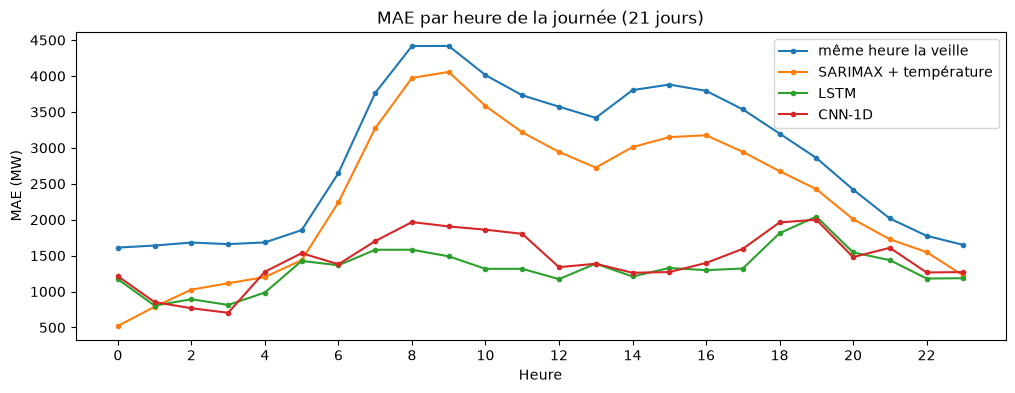

MAE par pli (MW)


,même heure la veille,SARIMAX + température,LSTM,CNN-1D
janvier,2307.0,2150.0,1522.0,1643.0
mai,4248.0,3154.0,1361.0,1444.0
août,2076.0,1695.0,1075.0,1263.0


Jours fériés prévus : ['2024-01-01', '2024-05-01']
MAE fériés / ordinaires (MW)


,même heure la veille,SARIMAX + température,LSTM,CNN-1D
férié,4289.0,4160.0,1780.0,2163.0
ordinaire,2729.0,2141.0,1271.0,1375.0


Les cinq pires jours du LSTM (MAE en MW)


,jour de semaine,LSTM,même heure la veille
jour,,,
2024-01-01,lun,1990.0,2536.0
2024-05-06,lun,1859.0,5256.0
2024-05-02,jeu,1822.0,6885.0
2024-08-07,mer,1822.0,528.0
2024-01-02,mar,1776.0,5996.0


In [10]:
noms = ["même heure la veille", "SARIMAX + température", "LSTM", "CNN-1D"]
jours_prevus = [te for _, jours in folds for te in jours]                       # 21 journées, dans l'ordre de PREDS
dates = [jour[te[0]] for te in jours_prevus]
reel = np.stack([yv[te] for te in jours_prevus])
err = {n: np.abs(PREDS[n].reshape(-1, H) - reel) for n in noms}
assert reel.shape == (21, 24)

# 1 : MAE par heure de la journée
fig, ax = plt.subplots(figsize=(12, 4))
for n in noms: ax.plot(range(H), err[n].mean(axis=0), marker="o", ms=3, label=n)
ax.set(title="MAE par heure de la journée (21 jours)", xlabel="Heure", ylabel="MAE (MW)", xticks=range(0, H, 2)); ax.legend(); plt.show()

# 2 : MAE par pli
noms_mois = {1: "janvier", 2: "février", 3: "mars", 4: "avril", 5: "mai", 6: "juin", 7: "juillet", 8: "août",
             9: "septembre", 10: "octobre", 11: "novembre", 12: "décembre"}
par_pli = pd.DataFrame({n: err[n].reshape(len(folds), 7, H).mean(axis=(1, 2)) for n in noms}, index=[noms_mois[m] for m in MOIS_TP])
print("MAE par pli (MW)"); display(par_pli.round(0))

# 3 : jours fériés contre jours ordinaires
ferie = np.array([df["jour_ferie"].values[te[0]] == 1 for te in jours_prevus])
print("Jours fériés prévus :", [d for d, f in zip(dates, ferie) if f])
par_type = pd.DataFrame({n: [err[n][ferie].mean(), err[n][~ferie].mean()] for n in noms}, index=["férié", "ordinaire"])
print("MAE fériés / ordinaires (MW)"); display(par_type.round(0))

# 4 : les cinq pires jours du LSTM, avec l'erreur de « la veille » ces jours-là
mae_j = pd.DataFrame({n: err[n].mean(axis=1) for n in noms}, index=pd.Index(dates, name="jour"))
mae_j["jour de semaine"] = [["lun", "mar", "mer", "jeu", "ven", "sam", "dim"][pd.Timestamp(d).dayofweek] for d in dates]
pires = mae_j.sort_values("LSTM", ascending=False).head(5)[["jour de semaine", "LSTM", "même heure la veille"]]
print("Les cinq pires jours du LSTM (MAE en MW)"); display(pires.round(0))

**À rédiger (3 lignes)** : à quelles heures le LSTM se trompe-t-il le plus ? Sur quel pli ? Les jours fériés lui coûtent-ils encore cher, et combien coûtent-ils à « la veille » ?

**Réponse.** Le LSTM se trompe surtout à la pointe du soir (19 h, environ 2 000 MW) et à la montée du matin (7 h-9 h, environ 1 600 MW) ; la nuit, il reste entre 800 et 1 200 MW. Son pli le plus difficile est janvier (1 522 MW, devant mai 1 361 et août 1 075), alors que pour « la veille » c'est mai, de très loin (4 248 MW). Les fériés lui coûtent encore +40 % (1 780 MW contre 1 271 les jours ordinaires), mais beaucoup moins qu'à « la veille » (4 289 contre 2 729 MW), qui paie surtout les lendemains de fériés (6 885 MW le 2 mai, 5 996 MW le 2 janvier) quand le LSTM reste sous 1 850 MW.

## Partie E — Les douze plis du protocole du projet, pour les baselines (15 min)

Le TP n'utilise que trois plis (janvier, mai, août). Le projet en demande **douze**, soit 2 016 heures. Pour les baselines, cela ne coûte rien : recalculez-les sur les douze plis et comparez. Les trois plis du TP étaient-ils représentatifs ? Quel mois est le plus difficile ?

,MAE 3 plis (MW),MAE 12 plis (MW)
dernière valeur connue,4420.0,4310.0
même heure la veille,2877.0,2486.0
même heure la semaine précédente,3774.0,2644.0


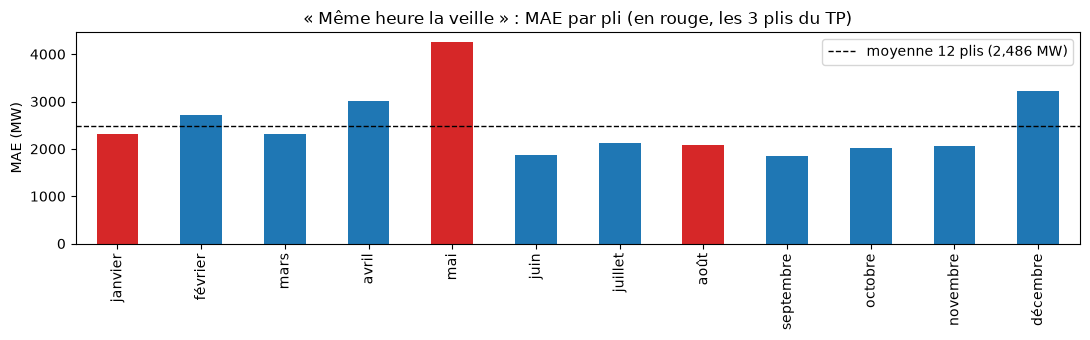

Mois le plus difficile : mai (4,248 MW) ; le plus facile : septembre (1,848 MW)


In [11]:
folds12 = plis(range(1, 13))
def scores_sur(plis_, predict_fn):
    vrai, pred = [], []
    for tr, jours in plis_:
        for te, pi in zip(jours, predict_fn(tr, jours)):
            vrai.append(yv[te]); pred.append(np.asarray(pi, float))
    return metrics(np.concatenate(vrai), np.concatenate(pred))
baselines = {"dernière valeur connue": derniere, "même heure la veille": veille, "même heure la semaine précédente": semaine}
comp = pd.DataFrame({"MAE 3 plis (MW)": [scores_sur(folds, f)["MAE (MW)"] for f in baselines.values()],
                     "MAE 12 plis (MW)": [scores_sur(folds12, f)["MAE (MW)"] for f in baselines.values()]}, index=list(baselines))
display(comp.round(0))
assert sum(len(te) for _, jours in folds12 for te in jours) == 2016

par_mois = pd.Series([scores_sur([f], veille)["MAE (MW)"] for f in folds12], index=[noms_mois[m] for m in range(1, 13)])
ax = par_mois.plot.bar(figsize=(11, 3.5), color=["tab:red" if m in MOIS_TP else "tab:blue" for m in range(1, 13)])
ax.axhline(par_mois.mean(), color="k", ls="--", lw=1, label=f"moyenne 12 plis ({par_mois.mean():,.0f} MW)")
ax.set(title="« Même heure la veille » : MAE par pli (en rouge, les 3 plis du TP)", ylabel="MAE (MW)"); ax.legend(); plt.tight_layout(); plt.show()
print(f"Mois le plus difficile : {par_mois.idxmax()} ({par_mois.max():,.0f} MW) ; le plus facile : {par_mois.idxmin()} ({par_mois.min():,.0f} MW)")

## Partie F — Ablation : que valent les covariables du lendemain ? (30 min)

Le LSTM reçoit deux choses : la semaine passée (168 h × 7 variables) et les **covariables connues du lendemain** (température prévue, heure, jour de semaine, jour férié). Laquelle fait gagner ? Une ablation répond : on retire un ingrédient et on mesure.

Entraînez deux LSTM identiques sur le pli de **mai** (celui du 1er mai), avec le même budget réduit (un an d'entraînement) : l'un complet, l'autre qui ne voit pas les covariables du lendemain (on les remplace par des zéros). Comparez jour par jour.

Deux entraînements : 28 s


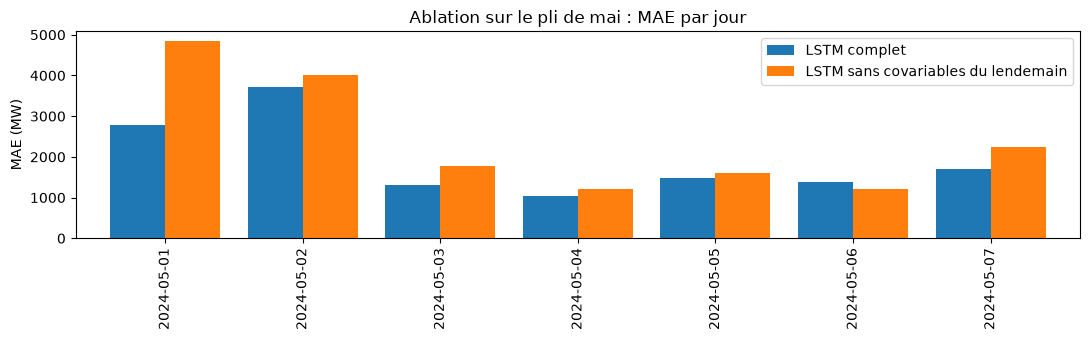

,LSTM complet,LSTM sans covariables du lendemain
2024-05-01,2794.0,4843.0
2024-05-02,3726.0,4008.0
2024-05-03,1307.0,1772.0
2024-05-04,1049.0,1200.0
2024-05-05,1487.0,1608.0
2024-05-06,1377.0,1200.0
2024-05-07,1700.0,2247.0


MAE moyenne (MW) : {'LSTM complet': 1920.0, 'LSTM sans covariables du lendemain': 2411.0}
1er mai : 4,843 MW sans les covariables contre 2,794 MW avec, soit x1.7


In [12]:
def mae_par_jour(predict_fn, k):
    tr, jours = folds[k]
    return [float(np.mean(np.abs(yv[te] - np.asarray(p)))) for te, p in zip(jours, predict_fn(tr, jours))]

class LSTMSansFutur(LSTMForecaster):
    def forward(self, xp, xf):
        return super().forward(xp, torch.zeros_like(xf))      # le réseau ne voit plus les covariables du lendemain

UN_AN = 24 * 365
t0 = time.time()
avec = mae_par_jour(dl_factory(LSTMForecaster, epochs=6, max_windows=UN_AN, seed=0, verbose=False), 1)
sans = mae_par_jour(dl_factory(LSTMSansFutur, epochs=6, max_windows=UN_AN, seed=0, verbose=False), 1)
print(f"Deux entraînements : {time.time() - t0:.0f} s")
assert len(avec) == 7 and len(sans) == 7

abl = pd.DataFrame({"LSTM complet": avec, "LSTM sans covariables du lendemain": sans}, index=[jour[te[0]] for te in folds[1][1]])
ax = abl.plot.bar(figsize=(11, 3.5), width=0.8)
ax.set(title="Ablation sur le pli de mai : MAE par jour", ylabel="MAE (MW)"); plt.tight_layout(); plt.show()
display(abl.round(0)); print("MAE moyenne (MW) :", abl.mean().round(0).to_dict())
print(f"1er mai : {sans[0]:,.0f} MW sans les covariables contre {avec[0]:,.0f} MW avec, soit x{sans[0] / avec[0]:.1f}")

**À rédiger (2 lignes)** : d'où vient l'avantage des réseaux sur SARIMA dans le tableau final : de l'architecture récurrente, ou des informations qu'on leur donne ?

**Réponse.** Surtout des informations qu'on leur donne : sans les covariables du lendemain, le même LSTM passe de 1 920 à 2 411 MW sur le pli de mai (+26 %), et de 2 794 à 4 843 MW le 1er mai, car il ne sait plus que le lendemain est férié ni quelle température il fera. L'architecture récurrente n'est pas la clé : le CNN-1D, sans aucune récurrence, avec les mêmes entrées, fait presque aussi bien (1 450 contre 1 320 MW), et le reste de l'avantage vient de l'apprentissage sur des années de données (contre trois semaines pour SARIMA) et de la non-linéarité.

## Partie G — Recherche d'hyperparamètres : au hasard, puis bayésienne (50 min)

Le LSTM du TP a été réglé à la main : learning rate 0,001, état caché 64, dropout 0,1. Sont-ce de bons choix ? On applique la méthode du rappel de ce matin :

1. **un jeu de validation qui respecte le temps** : sur le pli d'août, on met de côté les sept derniers jours de juillet. On s'entraîne sur ce qui précède, on compare les réglages sur ces sept jours, et on ne touche au test (les sept premiers jours d'août) qu'une seule fois, à la fin ;
2. **une recherche au hasard** : six réglages tirés au sort (learning rate en échelle log, taille de l'état caché, dropout) ;
3. **une recherche bayésienne** avec Optuna (`pip install optuna`), huit essais ;
4. **le verdict sur le test**, avec le même budget pour le réglage par défaut et pour le meilleur réglage trouvé.

Le budget est volontairement réduit (six mois de fenêtres, trois epochs par essai) pour tenir sur CPU : les MAE sont donc plus hautes que dans le tableau final. Sur GPU, augmentez `max_windows` et `epochs`.

In [13]:
tr_aout, jours_test = folds[2]
tr_fit = tr_aout[:-7 * H]                                    # le train d'août sans ses 7 derniers jours
jours_val = np.split(tr_aout[-7 * H:], 7)                    # 25-31 juillet, 7 journées de 24 h
assert len(jours_val) == 7 and all(len(j) == H for j in jours_val) and jour[jours_val[0][0]] == "2024-07-25"

def entrainer_et_valider(hp, tr, jours, epochs=3, max_windows=24 * 180, seed=0):
    fn = dl_factory(LSTMForecaster, epochs=epochs, max_windows=max_windows, lr=hp["lr"], hidden=int(hp["hidden"]),
                    dropout=hp["dropout"], seed=seed, verbose=False)
    p = fn(tr, jours)
    return metrics(np.concatenate([yv[te] for te in jours]), np.concatenate(p))["MAE (MW)"]

DEFAUT = {"lr": 1e-3, "hidden": 64, "dropout": 0.1}
rng = np.random.default_rng(0)
reglages = [("défaut", DEFAUT)] + [("hasard", {"lr": float(10 ** rng.uniform(-4, -2)), "hidden": int(rng.choice([32, 64, 128])),
                                              "dropout": float(rng.uniform(0, 0.4))}) for _ in range(6)]
essais = []
t0 = time.time()
for methode, hp in reglages:
    essais.append({"méthode": methode, **hp, "MAE validation (MW)": entrainer_et_valider(hp, tr_fit, jours_val)})
    print(f"{methode:7s} lr={hp['lr']:.2e} hidden={hp['hidden']:3d} dropout={hp['dropout']:.2f} -> {essais[-1]['MAE validation (MW)']:,.0f} MW")
print(f"Recherche au hasard : {time.time() - t0:.0f} s")
assert len(essais) == 7 and all("MAE validation (MW)" in e for e in essais)

défaut  lr=1.00e-03 hidden= 64 dropout=0.10 -> 2,024 MW
hasard  lr=1.88e-03 hidden= 64 dropout=0.02 -> 1,722 MW
hasard  lr=1.08e-04 hidden= 32 dropout=0.33 -> 6,855 MW
hasard  lr=6.69e-03 hidden= 64 dropout=0.29 -> 1,765 MW
hasard  lr=1.22e-03 hidden= 64 dropout=0.37 -> 1,918 MW
hasard  lr=4.28e-03 hidden=128 dropout=0.34 -> 1,669 MW
hasard  lr=1.17e-04 hidden= 32 dropout=0.29 -> 6,632 MW
Recherche au hasard : 32 s


### G2 — La même recherche, guidée par les essais précédents (Optuna)
Une fonction objectif qui reçoit un essai, propose un réglage, appelle `entrainer_et_valider` et renvoie la MAE de validation. Huit essais : les premiers sont tirés au hasard, les suivants sont choisis d'après les résultats.

Optuna, 8 essais : 49 s


,méthode,lr,hidden,dropout,MAE validation (MW)
0,optuna,0.00906,32,0.05,1098.0
1,optuna,0.00383,128,0.03,1541.0
2,hasard,0.00428,128,0.34,1669.0
3,hasard,0.00188,64,0.02,1722.0
4,hasard,0.00669,64,0.29,1765.0
5,optuna,0.00190,64,0.17,1835.0
6,optuna,0.00196,128,0.15,1857.0
7,hasard,0.00122,64,0.37,1918.0
8,optuna,0.00172,128,0.27,1964.0
9,défaut,0.00100,64,0.10,2024.0


Meilleur réglage : {'lr': 0.009062263471261952, 'hidden': 32, 'dropout': 0.04730977034757329}


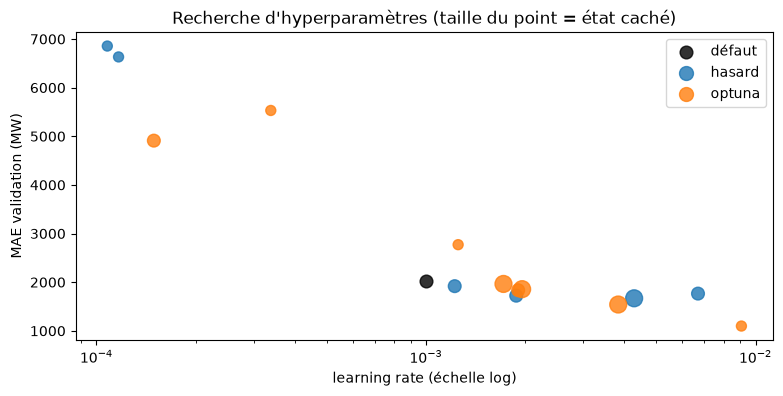

In [14]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
def objective(trial):
    hp = {"lr": trial.suggest_float("lr", 1e-4, 1e-2, log=True),
          "hidden": trial.suggest_categorical("hidden", [32, 64, 128]),
          "dropout": trial.suggest_float("dropout", 0.0, 0.4)}
    return entrainer_et_valider(hp, tr_fit, jours_val)
t0 = time.time()
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=0))
study.optimize(objective, n_trials=8)
print(f"Optuna, 8 essais : {time.time() - t0:.0f} s")
essais += [{"méthode": "optuna", **t.params, "MAE validation (MW)": t.value} for t in study.trials]
tableau = pd.DataFrame(essais).sort_values("MAE validation (MW)").reset_index(drop=True)
meilleur = {"lr": float(tableau.loc[0, "lr"]), "hidden": int(tableau.loc[0, "hidden"]), "dropout": float(tableau.loc[0, "dropout"])}
display(tableau.round({"lr": 5, "dropout": 2, "MAE validation (MW)": 0}))
print("Meilleur réglage :", meilleur)
assert tableau is not None and len(tableau) >= 7

fig, ax = plt.subplots(figsize=(9, 4))
for (methode, g), c in zip(tableau.groupby("méthode"), ["k", "tab:blue", "tab:orange"]):
    ax.scatter(g["lr"], g["MAE validation (MW)"], s=20 + g["hidden"], c=c, label=methode, alpha=0.8)
ax.set(xscale="log", xlabel="learning rate (échelle log)", ylabel="MAE validation (MW)",
       title="Recherche d'hyperparamètres (taille du point = état caché)"); ax.legend(); plt.show()

### G3 — Le verdict sur le test, une seule fois
On ré-entraîne le réglage par défaut et le meilleur réglage sur tout le train d'août (validation comprise), avec le même budget, et on mesure sur les sept premiers jours d'août. Le gain mesuré sur la validation se retrouve-t-il sur le test ? Ne soyez pas surpris s'il fond, ou s'il s'inverse : c'est le résultat le plus instructif de cette partie.

In [15]:
t0 = time.time()
mae_defaut = entrainer_et_valider(DEFAUT, tr_aout, jours_test)        # même budget : 3 epochs, six mois de fenêtres
mae_meilleur = entrainer_et_valider(meilleur, tr_aout, jours_test)
print(f"Deux entraînements : {time.time() - t0:.0f} s")
val_defaut = tableau.loc[tableau["méthode"] == "défaut", "MAE validation (MW)"].iloc[0]
verdict = pd.DataFrame({"MAE validation (MW)": [val_defaut, tableau.loc[0, "MAE validation (MW)"]],
                        "MAE test (MW)": [mae_defaut, mae_meilleur]}, index=["défaut", "meilleur trouvé"])
verdict.loc["gain (défaut - meilleur)"] = verdict.loc["défaut"] - verdict.loc["meilleur trouvé"]
display(verdict.round(0))
assert mae_defaut is not None and mae_meilleur is not None

Deux entraînements : 8 s


,MAE validation (MW),MAE test (MW)
défaut,2024.0,1639.0
meilleur trouvé,1098.0,2094.0
gain (défaut - meilleur),926.0,-455.0


**À rédiger (3 lignes)** : quel hyperparamètre compte le plus sur le nuage de points ? Le réglage par défaut du TP était-il raisonnable ? Pourquoi ne faut-il regarder le test qu'une seule fois ?

**Réponse.** Le learning rate domine : en dessous d'environ 3e-4, la MAE de validation monte à 5 000-7 000 MW (le réseau n'a pas convergé en trois epochs), alors qu'au-dessus de 1e-3 tous les essais sont entre 1 100 et 2 000 MW ; la taille de l'état caché et le dropout ne jouent qu'au second ordre. Le réglage par défaut (1e-3, 64, 0,1) était raisonnable, dans la bonne zone sans être optimal avec ce budget réduit (2 024 MW, 10e sur 15), et le test l'a d'ailleurs préféré : 1 639 MW contre 2 094 pour le « meilleur » réglage (1 098 MW en validation), un gain qui s'inverse parce qu'on a retenu, parmi quinze essais, celui qui collait le mieux à une seule semaine de juillet. Il ne faut regarder le test qu'une fois parce que choisir d'après lui en ferait un second jeu de validation : on y sur-ajusterait de la même façon, et la MAE annoncée ne mesurerait plus la performance sur des données vraiment inconnues.

**Pour le projet** : cette partie est le squelette de votre recherche d'hyperparamètres. À partir de J4, chaque appel à `entrainer_et_valider` deviendra un run MLflow (hyperparamètres en paramètres, MAE de validation en métrique).